# k-Nearest Neighbours, Naive Bayes & Logistic Regression (+ combined R3 table)
**F20DL Group 15 – Requirement R3 (classic ML models)** · Models: kNN, Gaussian Naive Bayes, Logistic Regression

Task: 5-class skin-disease classification on our cleaned Fitzpatrick17k subset (1,623 images).
Protocol shared by the whole group: fixed stratified split (train 1,136 / val 243 / test 244, seed 42) loaded only with
`load_split`; images resized to 32×32 RGB and flattened (3,072 features); **hyperparameters chosen on the validation set
using macro-F1**; the test set is used **once** at the very end. `random_state=42` everywhere and class imbalance handled
where the model supports it.

**Run order:** run `R3_decision_tree_random_forest.ipynb` first so its test scores are in `results/`; section 6 combines all five classic models.

## 1. Setup and package versions

In [1]:
import os, sys
DATA_DIR = next(p for p in ["../Fitzpatrick17k_processed", "Fitzpatrick17k_processed"] if os.path.exists(p))
sys.path.append(DATA_DIR)
from load_data import load_split, load_info, CLASS_NAMES

import sys, time, json, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib, sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
# save figures into documentation/figures if we're inside notebooks/
FIG_DIR = Path("../documentation/figures") if Path("../documentation").exists() else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# print package versions
print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
try:
    import PIL; print("pillow      ", PIL.__version__)
except ImportError:
    pass

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
matplotlib   3.11.2
pillow       13.0.0


## 2. Load the shared split

In [2]:
# load the fixed train/val/test split, 32x32 images flattened to 3072 features
X_train, y_train = load_split("train", size=32, flatten=True)
X_val,   y_val   = load_split("val",   size=32, flatten=True)
X_test,  y_test  = load_split("test",  size=32, flatten=True)
SHORT = ["ACD", "BCC", "Psor", "SebD", "Vit"]   # short names for plot labels

print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)
print(pd.DataFrame({s: np.bincount(y, minlength=len(CLASS_NAMES)) for s, y in
                    [("train", y_train), ("val", y_val), ("test", y_test)]}, index=CLASS_NAMES))

train (1136, 3072) val (243, 3072) test (244, 3072)
                             train  val  test
allergic contact dermatitis    267   57    57
basal cell carcinoma           248   53    54
psoriasis                      423   91    90
seborrheic dermatitis           86   18    19
vitiligo                       112   24    24


## 3. Helper functions (validation search + one-off test evaluation)

In [3]:
# helper functions used for every model
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def tune_on_val(make_model, grid, name):
    # train each setting on train, score macro-F1 on val (test not used here)
    rows = []
    for params in grid:
        t0 = time.time()
        m = make_model(**params).fit(X_train, y_train)
        rows.append({**params,
                     "train_macro_f1": macro_f1(y_train, m.predict(X_train)),
                     "val_macro_f1": macro_f1(y_val, m.predict(X_val)),
                     "val_acc": accuracy_score(y_val, m.predict(X_val)),
                     "fit_s": round(time.time() - t0, 2)})
    df = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
    df.to_csv(RESULTS_DIR / f"{name}_val_search.csv", index=False)
    return df

def best_params(df, keys):
    row = df.iloc[0]
    out = {}
    for k in keys:
        v = row[k]
        if isinstance(v, float) and np.isnan(v): v = None
        elif isinstance(v, np.integer): v = int(v)
        elif isinstance(v, np.floating) and float(v).is_integer() and k not in FLOAT_KEYS: v = int(v)
        elif isinstance(v, np.floating): v = float(v)
        out[k] = v
    return out

FLOAT_KEYS = {"C", "var_smoothing", "max_features"}

def evaluate_on_test(model, name, params):
    # final test evaluation, prints report, saves confusion matrix + scores
    y_pred = model.predict(X_test)
    acc, mf1 = accuracy_score(y_test, y_pred), macro_f1(y_test, y_pred)
    p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=range(len(CLASS_NAMES)), zero_division=0)
    print(f"{name}: TEST accuracy = {acc:.3f} | TEST macro-F1 = {mf1:.3f}\n")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))

    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=SHORT).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} (test) – macro-F1 {mf1:.2f}")
    plt.tight_layout(); fig.savefig(FIG_DIR / f"cm_{name}.png", dpi=200); plt.show()

    res = {"model": name, "test_accuracy": round(acc, 4), "test_macro_f1": round(mf1, 4),
           "params": json.dumps(params, default=str)}
    for i, c in enumerate(SHORT):
        res[f"P_{c}"], res[f"R_{c}"] = round(p[i], 3), round(r[i], 3)
    pd.DataFrame([res]).to_csv(RESULTS_DIR / f"test_{name}.csv", index=False)
    return res

In [4]:
# imports for the pipelines
from itertools import product
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_sample_weight

## 4a. k-Nearest Neighbours

**Why these choices?**
- `StandardScaler` first: kNN is distance based, so every feature should be on the same scale.
- `PCA` with `n_components` ∈ {None, 50, 100}: in 3,072 dimensions distances become nearly equal (curse of dimensionality); projecting to the main 50–100 directions of variation usually makes neighbours more meaningful. `None` = no PCA, as a reference.
- `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31}: small k = flexible/noisy, large k = smooth/biased towards big classes; odd values avoid ties.
- `weights` ∈ {uniform, distance}: `distance` lets closer neighbours count more, which also partly protects minority classes from being out-voted.
- `metric` ∈ {euclidean, manhattan}: the two standard Minkowski distances (p=2, p=1).
- Imbalance: `KNeighborsClassifier` has no `class_weight` option, so we rely on distance weighting and choose by macro-F1, which rewards minority-class recall. (kNN has no randomness, but PCA uses `random_state=42`.)

In [5]:
# knn pipeline (scale -> optional pca -> knn) and grid search
from sklearn.neighbors import KNeighborsClassifier

def make_knn(pca=None, n_neighbors=5, weights="uniform", metric="euclidean"):
    steps = [StandardScaler()]
    if pca is not None and not (isinstance(pca, float) and np.isnan(pca)):
        steps.append(PCA(n_components=int(pca), random_state=RANDOM_STATE))
    steps.append(KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, metric=metric))
    return make_pipeline(*steps)

knn_grid = [dict(pca=p, n_neighbors=k, weights=w, metric=m) for p, k, w, m in
            product([None, 50, 100], [1, 3, 5, 7, 11, 15, 21, 31], ["uniform", "distance"], ["euclidean", "manhattan"])]
knn_search = tune_on_val(make_knn, knn_grid, "kNN")
knn_search.head(8)

,pca,n_neighbors,weights,metric,train_macro_f1,val_macro_f1,val_acc,fit_s
0,50.0,1,distance,euclidean,1.0,0.403037,0.465021,0.49
1,50.0,1,uniform,euclidean,1.0,0.403037,0.465021,0.93
2,50.0,3,distance,euclidean,1.0,0.394619,0.489712,0.93
3,50.0,5,distance,manhattan,1.0,0.393012,0.460905,1.21
4,NaN,1,uniform,manhattan,1.0,0.379281,0.452675,3.00
5,NaN,1,distance,manhattan,1.0,0.379281,0.452675,2.45
6,NaN,1,uniform,euclidean,1.0,0.378927,0.436214,0.35
7,NaN,1,distance,euclidean,1.0,0.378927,0.436214,0.21


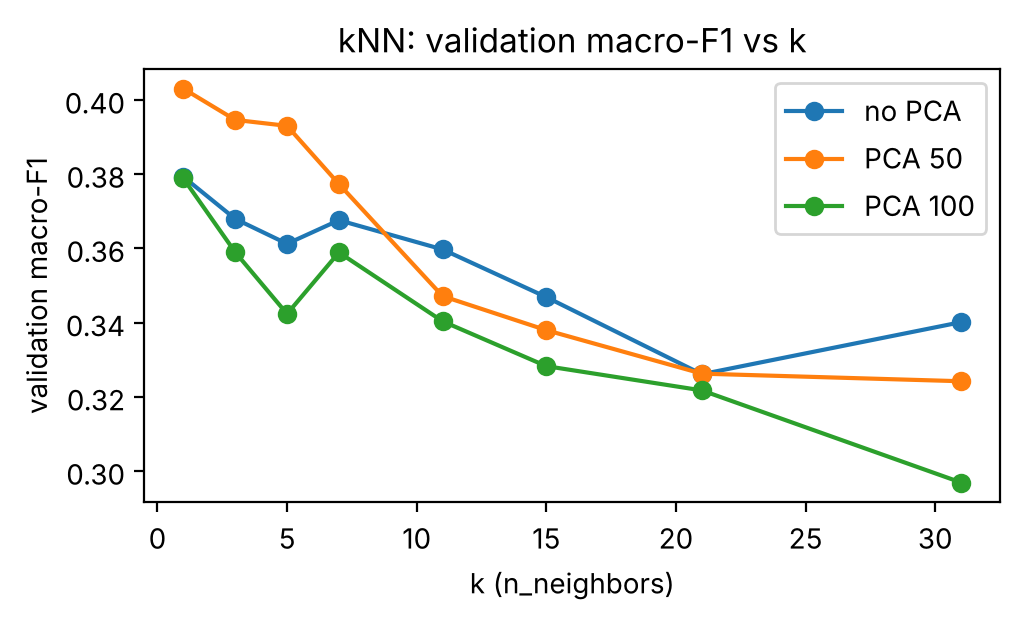

In [6]:
# val macro-F1 vs k
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for p, g in knn_search.assign(pca=knn_search.pca.fillna(0)).groupby("pca"):
    c = g.groupby("n_neighbors").val_macro_f1.max(); ax.plot(c.index, c.values, marker="o", label=f"PCA {int(p)}" if p else "no PCA")
ax.set_xlabel("k (n_neighbors)"); ax.set_ylabel("validation macro-F1"); ax.legend(); ax.set_title("kNN: validation macro-F1 vs k")
plt.tight_layout(); plt.savefig(FIG_DIR / "knn_k_curve.png", dpi=200); plt.show()

Chosen kNN hyperparameters (by validation macro-F1): {'pca': 50, 'n_neighbors': 1, 'weights': 'distance', 'metric': 'euclidean'}


kNN: TEST accuracy = 0.480 | TEST macro-F1 = 0.428

                             precision    recall  f1-score   support

allergic contact dermatitis      0.415     0.386     0.400        57
       basal cell carcinoma      0.452     0.519     0.483        54
                  psoriasis      0.574     0.600     0.587        90
      seborrheic dermatitis      0.238     0.263     0.250        19
                   vitiligo      0.571     0.333     0.421        24

                   accuracy                          0.480       244
                  macro avg      0.450     0.420     0.428       244
               weighted avg      0.484     0.480     0.478       244



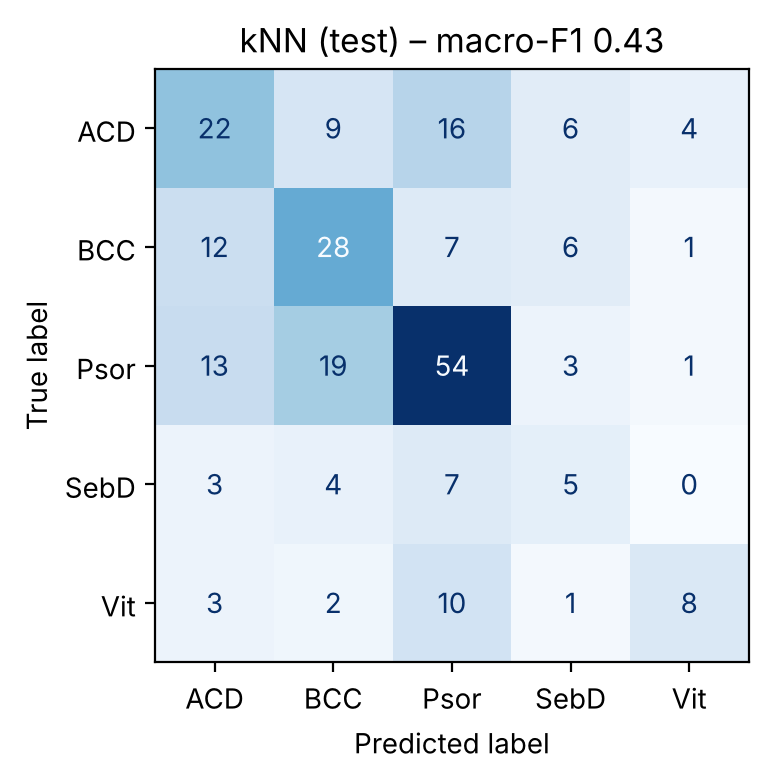

In [7]:
# pick best params, retrain and test
knn_best = best_params(knn_search, ["pca", "n_neighbors", "weights", "metric"])
print("Chosen kNN hyperparameters (by validation macro-F1):", knn_best)
knn_model = make_knn(**knn_best).fit(X_train, y_train)
knn_res = evaluate_on_test(knn_model, "kNN", knn_best)

## 4b. Gaussian Naive Bayes

**Why these choices?**
- Gaussian NB because the features are continuous pixel intensities.
- `PCA` ∈ {None, 20, 50, 100}: NB assumes features are independent given the class; neighbouring pixels are strongly correlated, which breaks this assumption badly. PCA components are uncorrelated, so NB on PCA features is a fairer test of the model.
- `var_smoothing` ∈ {1e-9, 1e-6, 1e-3, 1e-2, 1e-1}: adds a fraction of the largest feature variance to every variance for numerical stability; larger values make the class densities flatter (more regularised). 1e-9 is the library default.
- Imbalance: `GaussianNB` has no `class_weight`, so we pass `priors` ∈ {empirical, uniform}. Uniform priors (0.2 each) are the NB equivalent of balanced class weights: they stop the frequent class (psoriasis) winning just because it is common.

In [8]:
# naive bayes pipeline and grid search
from sklearn.naive_bayes import GaussianNB

K = len(CLASS_NAMES)
def make_nb(pca=None, var_smoothing=1e-9, priors="empirical"):
    steps = [StandardScaler()]
    if pca is not None and not (isinstance(pca, float) and np.isnan(pca)):
        steps.append(PCA(n_components=int(pca), random_state=RANDOM_STATE))
    steps.append(GaussianNB(var_smoothing=var_smoothing, priors=[1 / K] * K if priors == "uniform" else None))
    return make_pipeline(*steps)

nb_grid = [dict(pca=p, var_smoothing=v, priors=pr) for p, v, pr in
           product([None, 20, 50, 100], [1e-9, 1e-6, 1e-3, 1e-2, 1e-1], ["empirical", "uniform"])]
nb_search = tune_on_val(make_nb, nb_grid, "NaiveBayes")
nb_search.head(8)

,pca,var_smoothing,priors,train_macro_f1,val_macro_f1,val_acc,fit_s
0,20.0,1.000000e-06,empirical,0.331843,0.331053,0.415638,0.46
1,20.0,1.000000e-09,empirical,0.331843,0.331053,0.415638,0.43
2,20.0,1.000000e-02,empirical,0.320420,0.328285,0.427984,0.32
3,20.0,1.000000e-02,uniform,0.322781,0.321741,0.370370,0.35
4,50.0,1.000000e-02,uniform,0.329186,0.321114,0.370370,0.57
5,100.0,1.000000e-02,uniform,0.317718,0.320904,0.362140,0.68
6,20.0,1.000000e-03,empirical,0.329237,0.319503,0.411523,0.33
7,50.0,1.000000e-02,empirical,0.339188,0.311745,0.378601,0.86


Chosen Naive Bayes hyperparameters (by validation macro-F1): {'pca': 20, 'var_smoothing': 1e-06, 'priors': 'empirical'}
NaiveBayes: TEST accuracy = 0.398 | TEST macro-F1 = 0.289

                             precision    recall  f1-score   support

allergic contact dermatitis      0.294     0.088     0.135        57
       basal cell carcinoma      0.364     0.796     0.500        54
                  psoriasis      0.519     0.467     0.491        90
      seborrheic dermatitis      0.000     0.000     0.000        19
                   vitiligo      0.350     0.292     0.318        24

                   accuracy                          0.398       244
                  macro avg      0.305     0.328     0.289       244
               weighted avg      0.375     0.398     0.355       244



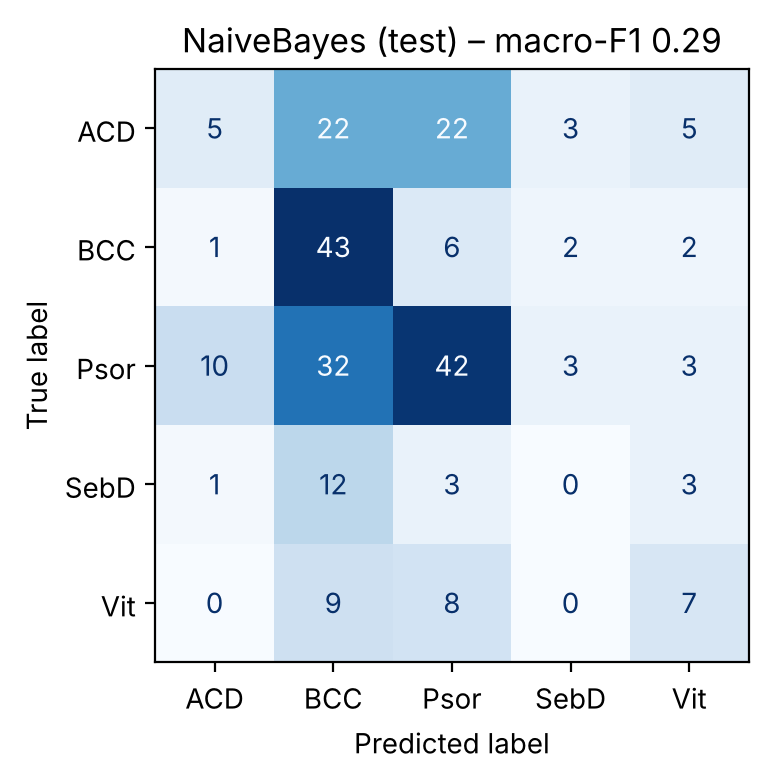

In [9]:
# pick best params, retrain and test
nb_best = best_params(nb_search, ["pca", "var_smoothing", "priors"])
print("Chosen Naive Bayes hyperparameters (by validation macro-F1):", nb_best)
nb_model = make_nb(**nb_best).fit(X_train, y_train)
nb_res = evaluate_on_test(nb_model, "NaiveBayes", nb_best)

## 4c. Logistic Regression (multinomial)

**Why these choices?**
- `StandardScaler`: needed so the L2 penalty treats all pixels equally and the solver converges.
- `C` ∈ {1e-4, 3e-4, 1e-3, 3e-3, 0.01, 0.03, 0.1, 1}: inverse regularisation strength. We have more features (3,072) than training images (1,136), so the model can fit the training set perfectly unless it is strongly regularised; the grid is therefore weighted towards small C, on a log scale.
- `PCA` ∈ {None, 100}: a second way to control complexity (fewer, decorrelated inputs).
- `penalty="l2"`, `solver="lbfgs"`, `max_iter=5000`: standard, stable multinomial set-up; max_iter raised so every setting converges.
- `class_weight="balanced"` (fixed) for the class imbalance.

In [10]:
# logistic regression pipeline and grid search over C
from sklearn.linear_model import LogisticRegression

def make_lr(pca=None, C=1.0):
    steps = [StandardScaler()]
    if pca is not None and not (isinstance(pca, float) and np.isnan(pca)):
        steps.append(PCA(n_components=int(pca), random_state=RANDOM_STATE))
    steps.append(LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE))
    return make_pipeline(*steps)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lr_grid = [dict(pca=p, C=c) for p, c in product([None, 100], [1e-4, 3e-4, 1e-3, 3e-3, 0.01, 0.03, 0.1, 1.0])]
    lr_search = tune_on_val(make_lr, lr_grid, "LogisticRegression")
lr_search.head(8)

,pca,C,train_macro_f1,val_macro_f1,val_acc,fit_s
0,NaN,0.0003,0.496006,0.365725,0.403292,6.78
1,100.0,0.0003,0.449798,0.364570,0.395062,1.14
2,NaN,0.1000,0.985560,0.353809,0.407407,17.15
3,NaN,0.0010,0.593174,0.351242,0.395062,5.96
4,NaN,0.0001,0.426936,0.350746,0.386831,2.74
5,NaN,1.0000,1.000000,0.349761,0.390947,14.85
6,NaN,0.0030,0.708668,0.348062,0.407407,8.14
7,NaN,0.0300,0.930642,0.343014,0.395062,17.18


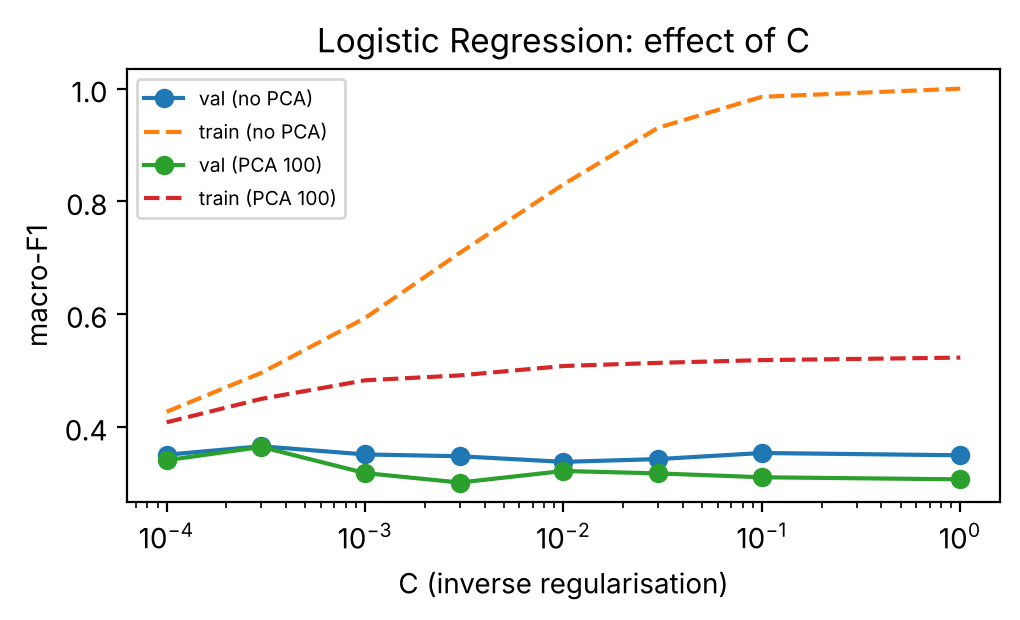

In [11]:
# train vs val macro-F1 for each C
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for p, g in lr_search.assign(pca=lr_search.pca.fillna(0)).groupby("pca"):
    g = g.sort_values("C"); lab = f"PCA {int(p)}" if p else "no PCA"
    ax.semilogx(g.C, g.val_macro_f1, marker="o", label=f"val ({lab})"); ax.semilogx(g.C, g.train_macro_f1, ls="--", label=f"train ({lab})")
ax.set_xlabel("C (inverse regularisation)"); ax.set_ylabel("macro-F1"); ax.legend(fontsize=7); ax.set_title("Logistic Regression: effect of C")
plt.tight_layout(); plt.savefig(FIG_DIR / "lr_C_curve.png", dpi=200); plt.show()

Chosen Logistic Regression hyperparameters (by validation macro-F1): {'pca': None, 'C': 0.0003}


LogisticRegression: TEST accuracy = 0.393 | TEST macro-F1 = 0.363

                             precision    recall  f1-score   support

allergic contact dermatitis      0.375     0.211     0.270        57
       basal cell carcinoma      0.530     0.648     0.583        54
                  psoriasis      0.574     0.344     0.431        90
      seborrheic dermatitis      0.191     0.474     0.273        19
                   vitiligo      0.200     0.375     0.261        24

                   accuracy                          0.393       244
                  macro avg      0.374     0.410     0.363       244
               weighted avg      0.451     0.393     0.398       244



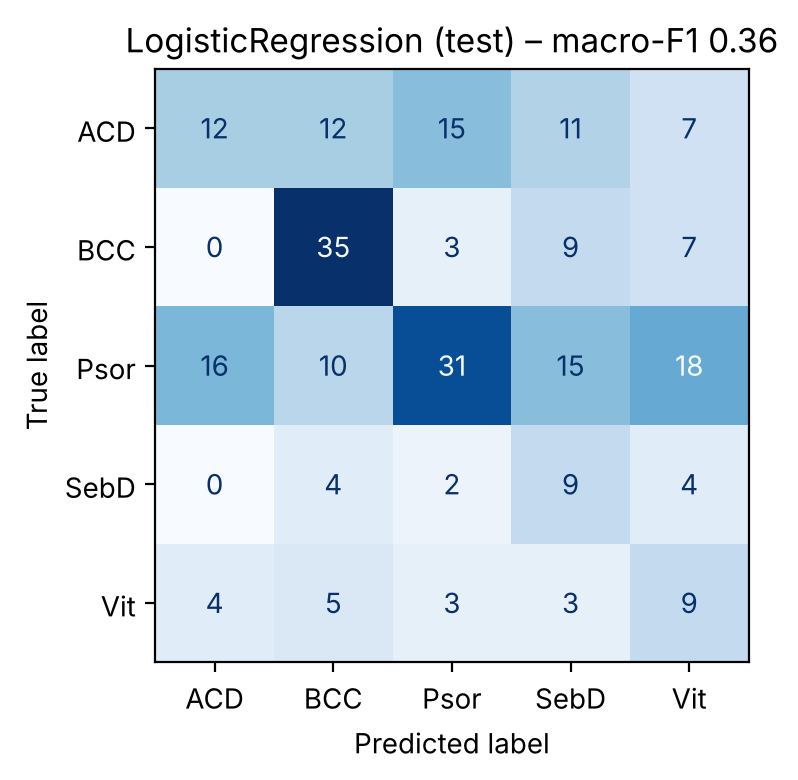

In [12]:
# pick best params, retrain and test
lr_best = best_params(lr_search, ["pca", "C"])
print("Chosen Logistic Regression hyperparameters (by validation macro-F1):", lr_best)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lr_model = make_lr(**lr_best).fit(X_train, y_train)
lr_res = evaluate_on_test(lr_model, "LogisticRegression", lr_best)

## 5. Baseline

A trivial baseline gives the floor every model must beat: a `DummyClassifier(strategy="stratified")` guesses classes at their training frequencies (macro-F1 ≈ 0.2 by chance); `most_frequent` always predicts psoriasis.

In [13]:
# dummy baselines to compare against
from sklearn.dummy import DummyClassifier
base_rows = []
for strat in ["most_frequent", "stratified"]:
    d = DummyClassifier(strategy=strat, random_state=RANDOM_STATE).fit(X_train, y_train)
    yp = d.predict(X_test)
    base_rows.append({"model": f"Baseline ({strat})", "test_accuracy": round(accuracy_score(y_test, yp), 4),
                      "test_macro_f1": round(macro_f1(y_test, yp), 4)})
pd.DataFrame(base_rows)

,model,test_accuracy,test_macro_f1
0,Baseline (most_frequent),0.3689,0.1078
1,Baseline (stratified),0.2418,0.1966


## 6. Combined R3 comparison table (all five classic models)

Reads the test scores saved by both notebooks (`results/test_*.csv`). Same split, same 32×32 features, same metric, so the numbers are directly comparable.

In [14]:
# combine the saved test scores of all 5 models into one table
order = ["DecisionTree", "RandomForest", "kNN", "NaiveBayes", "LogisticRegression"]
rows = []
for m in order:
    f = RESULTS_DIR / f"test_{m}.csv"
    if f.exists(): rows.append(pd.read_csv(f).iloc[0].to_dict())
    else: print(f"(missing {f} – run the Decision Tree / Random Forest notebook first)")
table = pd.concat([pd.DataFrame(rows), pd.DataFrame(base_rows)], ignore_index=True)
cols = ["model", "test_macro_f1", "test_accuracy"] + [f"R_{c}" for c in SHORT] + ["params"]
table = table[[c for c in cols if c in table]].sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
table.to_csv(RESULTS_DIR / "R3_comparison_table.csv", index=False)
table

,model,test_macro_f1,test_accuracy,R_ACD,R_BCC,R_Psor,R_SebD,R_Vit,params
0,RandomForest,0.4329,0.4959,0.316,0.593,0.633,0.211,0.417,"{""n_estimators"": 200, ""max_features"": 0.1, ""mi..."
1,kNN,0.4282,0.4795,0.386,0.519,0.600,0.263,0.333,"{""pca"": 50, ""n_neighbors"": 1, ""weights"": ""dist..."
2,LogisticRegression,0.3634,0.3934,0.211,0.648,0.344,0.474,0.375,"{""pca"": null, ""C"": 0.0003}"
3,DecisionTree,0.3074,0.3648,0.351,0.370,0.456,0.158,0.208,"{""max_depth"": 20, ""min_samples_leaf"": 1, ""crit..."
4,NaiveBayes,0.2889,0.3975,0.088,0.796,0.467,0.000,0.292,"{""pca"": 20, ""var_smoothing"": 1e-06, ""priors"": ..."
5,Baseline (stratified),0.1966,0.2418,NaN,NaN,NaN,NaN,NaN,NaN
6,Baseline (most_frequent),0.1078,0.3689,NaN,NaN,NaN,NaN,NaN,NaN


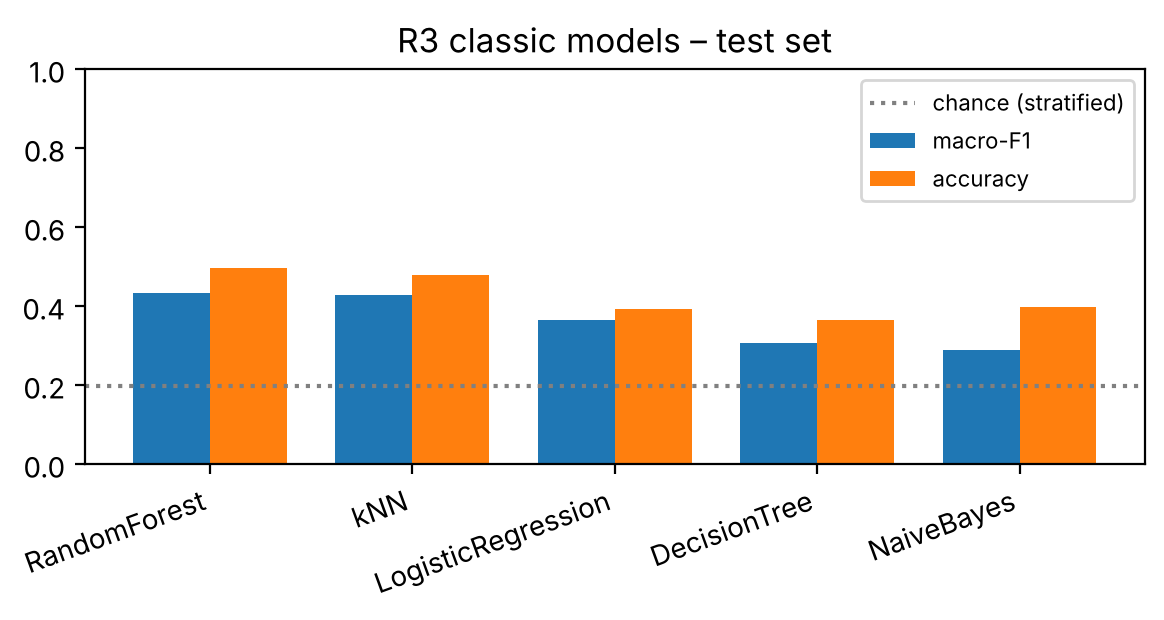

In [15]:
# bar chart of the comparison table
t = table[~table.model.str.startswith("Baseline")]
fig, ax = plt.subplots(figsize=(6, 3.2))
x = np.arange(len(t)); w = 0.38
ax.bar(x - w/2, t.test_macro_f1, w, label="macro-F1"); ax.bar(x + w/2, t.test_accuracy, w, label="accuracy")
ax.axhline(table.loc[table.model == "Baseline (stratified)", "test_macro_f1"].values[0], ls=":", c="grey", label="chance (stratified)")
ax.set_xticks(x); ax.set_xticklabels(t.model, rotation=20, ha="right"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
ax.set_title("R3 classic models – test set"); plt.tight_layout(); plt.savefig(FIG_DIR / "R3_comparison.png", dpi=200); plt.show()

**Interpretation.** Random Forest (0.43 macro-F1) and kNN (0.43) are clearly the best classic models; Logistic Regression is next (0.36),
then Decision Tree (0.31) and Naive Bayes (0.29). All beat the chance baseline (0.20). kNN worked best after PCA to 50 components with k=1,
i.e. it relies on finding a near-identical training photo, which is fragile. Logistic Regression needed very strong regularisation (C=3e-4)
because it has 3,072 features for 1,136 images; with balanced class weights it gives the best seborrheic dermatitis recall (0.47) of any model,
at the cost of psoriasis recall. Naive Bayes is worst because its independence assumption does not fit image data, even after PCA, and it never
predicts seborrheic dermatitis correctly. Raw 32×32 pixels lose texture and fine detail, so these scores are a lower bound for the CNNs in R4.

**Caution on BCC:** basal cell carcinoma is a top-recall class for most models (LR 0.65, NB 0.80, RF 0.59). The R2 analysis found ≈72% of BCC images carry the source atlas's watermark, and the Random Forest importance map has a hot spot in the bottom-left corner, so models may partly use the watermark rather than the lesion.

## 7. Fairness check: test scores by skin tone (Fitzpatrick scale)

Fitzpatrick17k is known for under-representing darker skin, so we check whether our models do worse on it.
This is analysis only (no tuning): test predictions are grouped by `fitzpatrick_scale` from `dataset.csv`
(via `load_info`, same row order as `load_split`). Groups: light = 1–2, medium = 3–4, dark = 5–6, unknown = -1.
Only 36 test images are dark skin (and 6 unknown), so these per-group scores are noisy. In our run, kNN's macro-F1 drops from 0.43 on light skin to 0.27 on dark skin, while Logistic Regression is roughly even across groups.

In [16]:
# test scores split by skin tone
from load_data import load_info
fst = np.array([int(r["fitzpatrick_scale"]) for r in load_info("test")])
assert len(fst) == len(y_test)
tone = np.select([fst <= 0, fst <= 2, fst <= 4], ["unknown", "light (1-2)", "medium (3-4)"], "dark (5-6)")
rows = []
for name, m in [("kNN", knn_model), ("NaiveBayes", nb_model), ("LogisticRegression", lr_model)]:
    yp = m.predict(X_test)
    for g in ["light (1-2)", "medium (3-4)", "dark (5-6)", "unknown"]:
        k = tone == g
        if k.sum(): rows.append({"model": name, "skin tone": g, "n": int(k.sum()),
                                 "accuracy": round(accuracy_score(y_test[k], yp[k]), 3),
                                 "macro_f1": round(macro_f1(y_test[k], yp[k]), 3)})
by_tone = pd.DataFrame(rows); by_tone.to_csv(RESULTS_DIR / "R3_by_skin_tone.csv", index=False)
by_tone.pivot(index="model", columns="skin tone", values="accuracy")

skin tone,dark (5-6),light (1-2),medium (3-4),unknown
model,,,,
LogisticRegression,0.417,0.380,0.415,0.167
NaiveBayes,0.444,0.389,0.404,0.167
kNN,0.472,0.556,0.383,0.667


In [17]:
# how many test images per skin tone group
by_tone.pivot(index="skin tone", columns="model", values="n").iloc[:, :1].rename(columns=lambda c: "n test images")

model,n test images
skin tone,
dark (5-6),36
light (1-2),108
medium (3-4),94
unknown,6
